Name: Shubhajeet Das <br />
Roll No.: 24AI10013 <br />

Task: Predict the closing value of the stock

1. Loading Dataset (1 marks)
    a. Load the dataset and display the first 5 rows, column names and shape.
2. Preprocessing (4 marks)
    a. Strip “$” from price columns and convert datatype to float. (2 marks)
    b. Fix mixed date formats (MM/DD/YYYY and MM-DD-YYYY), to DD/MM/YYYY format and perform linear interpolation of the missing dates. (2 marks)
3. Data Preparation (3 marks)
    a. Split into train/val/test (70-15-15) chronologically and scale the data and fit only on train set. (1 marks)
    b. Take seq_len = 15 and construct the respective sequences and load the data using Data Loaders. (2 marks)
4. Stacked RNN (12 marks)
    a. Implement a RNN cell from scratch, and using it stack 2 of them with the following parameters- (7 marks)
                ◦ Initialize weights by a uniform distribution where k = 1/(√ (hidden size))
                ◦ Hidden size =64
                ◦ MSE Loss
                ◦ ADAM Optimizer
                ◦ Batch Size = 32
                ◦ Lr = 0.001
                ◦ Add a fully connected layer having the following neurons [64,1] with ReLU activation.
    b. Train the model for 20 epochs. (2 marks)
    c. Plot the training and validation losses. (1 marks)
    d. Evaluate on the test set and report R2 and MSE scores. (2 marks)
5. Bidirectional RNN (15 marks)
    a. Implement a Bi-RNN using the same RNN cell (forward + backward, concatenated),and use the same parameters as before. (10 marks)
    b. Train the model for 20 epochs. (2 marks)
    c. Plot the training and validation losses. (1 marks)
    d. Evaluate on the test set and report R2 and MSE scores. (2 marks)
6. Attention-based RNN (15 marks)
    a. Implement an RNN with an attention layer that scores odd and even timesteps using two separate learned vectors, softmax over the sequence, weighted sum as context. For this question, you may directly use nn.RNN. Use the same parameters as before. (10 marks)
    b. Train for 20 epochs. (2 marks)
    c. Plot the training and validation losses. (1 marks)
    d. Evaluate on the test set and report R2 and MSE scores. (2 marks)

In [1]:
import torch
import numpy as np
SEED = 10
torch.manual_seed(SEED)
np.random.seed(SEED)

### TASK 1

In [2]:
# Dataset /content/HistoricalQuotes.csv
import pandas as pd
df = pd.read_csv('/content/HistoricalQuotes.csv')
df.head()

,Date,Close,Volume,Open,High,Low
0,02/28/2020,$273.36,106721200,$257.26,$278.41,$256.37
1,02/27/2020,$273.52,80151380,$281.1,$286,$272.96
2,02/26/2020,$292.65,49678430,$286.53,$297.88,$286.5
3,02/25/2020,$288.08,57668360,$300.95,$302.53,$286.13
4,02/24/2020,$298.18,55548830,$297.26,$304.18,$289.23


In [3]:
df.columns

Index(['Date', 'Close', 'Volume', 'Open', 'High', 'Low'], dtype='object')

In [4]:
df.shape

(2518, 6)

### TASK 2

In [5]:
for col in ['Close', 'Open', 'High', 'Low']:
    df[col] = df[col].str.replace('$', '', regex=False).astype(float)

In [6]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
# Drop rows where 'Date' could not be parsed (are NaT) before sorting and setting index
df.dropna(subset=['Date'], inplace=True)
# ensure correct chronological order for interpolation
df = df.sort_values(by='Date').reset_index(drop=True)
# Check for any remaining missing dates after conversion (should be 0 now)
missing_dates_after_conversion = df['Date'].isnull().sum()
if missing_dates_after_conversion > 0:
    print(f"Warning: {missing_dates_after_conversion} dates could not be parsed and are NaT. These will be dropped or handled based on reindexing.")
# date range from the min to max date in the dataset
min_date = df['Date'].min()
max_date = df['Date'].max()
full_date_range = pd.date_range(start=min_date, end=max_date, freq='D')
# Set 'Date' as index to reindex and interpolate
df = df.set_index('Date')
# Reindex the DataFrame to include all dates in the full_date_range
df = df.reindex(full_date_range)
# Interpolate missing values
for col in ['Close', 'Volume', 'Open', 'High', 'Low']:
    df[col] = df[col].interpolate(method='linear')
# Reset index to make 'Date' a column again
df = df.reset_index().rename(columns={'index': 'Date'})
df.head()

,Date,Close,Volume,Open,High,Low
0,2010-03-15,31.9771,123005437.0,32.1971,32.2143,31.4643
1,2010-03-16,32.0643,111581993.0,32.0257,32.1400,31.7871
2,2010-03-17,32.0171,112501374.0,32.1286,32.3500,31.8957
3,2010-03-18,32.0928,85156076.0,32.0143,32.1428,31.8014
4,2010-03-19,31.7500,139669082.0,32.1128,32.1771,31.6043


### TASK 3: Data Preparation

In [7]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Extract the 'Close' prices for prediction
close_prices = df['Close'].values.reshape(-1, 1)

# Split data chronologically (70-15-15)
train_size = int(len(close_prices) * 0.70)
val_size = int(len(close_prices) * 0.15)
test_size = len(close_prices) - train_size - val_size

train_data = close_prices[0:train_size, :]
val_data = close_prices[train_size:train_size + val_size, :]
test_data = close_prices[train_size + val_size:len(close_prices), :]

print(f"Train data shape: {train_data.shape}")
print(f"Validation data shape: {val_data.shape}")
print(f"Test data shape: {test_data.shape}")

Train data shape: (2546, 1)
Validation data shape: (545, 1)
Test data shape: (547, 1)


In [8]:
# Scale the data (fit only on the training set)
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_data)
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

print("Data scaled successfully.")
# Display a few scaled values to verify
print("First 5 scaled training values:", train_scaled[:5].flatten())
print("First 5 scaled validation values:", val_scaled[:5].flatten())
print("First 5 scaled test values:", test_scaled[:5].flatten())

Data scaled successfully.
First 5 scaled training values: [0.00214752 0.0029721  0.00252577 0.00324161 0.        ]
First 5 scaled validation values: [1.00160757 1.00321513 1.0048227  1.00643026 1.00803783]
First 5 scaled test values: [1.85229314 1.85140571 1.85051828 1.84963084 1.84874341]


In [9]:
# Function to create sequences for RNN
def create_sequences(data, seq_len):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:(i + seq_len), 0])
        y.append(data[i + seq_len, 0])
    return np.array(X), np.array(y)

seq_len = 15

X_train, y_train = create_sequences(train_scaled, seq_len)
X_val, y_val = create_sequences(val_scaled, seq_len)
X_test, y_test = create_sequences(test_scaled, seq_len)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}, y_val shape: {y_val.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (2531, 15), y_train shape: (2531,)
X_val shape: (530, 15), y_val shape: (530,)
X_test shape: (532, 15), y_test shape: (532,)


In [10]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.from_numpy(X_train).float()
y_train_tensor = torch.from_numpy(y_train).float()
X_val_tensor = torch.from_numpy(X_val).float()
y_val_tensor = torch.from_numpy(y_val).float()
X_test_tensor = torch.from_numpy(X_test).float()
y_test_tensor = torch.from_numpy(y_test).float()

# Reshape X to be (batch_size, seq_len, num_features)
# Here, num_features is 1 since we are predicting 'Close' price only.
X_train_tensor = X_train_tensor.unsqueeze(-1)
X_val_tensor = X_val_tensor.unsqueeze(-1)
X_test_tensor = X_test_tensor.unsqueeze(-1)

batch_size = 32

# Create TensorDatasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("DataLoaders created successfully.")
# Display the first batch from the train_loader to verify
for X_batch, y_batch in train_loader:
    print(f"First X_train batch shape: {X_batch.shape}")
    print(f"First y_train batch shape: {y_batch.shape}")
    break

DataLoaders created successfully.
First X_train batch shape: torch.Size([32, 15, 1])
First y_train batch shape: torch.Size([32])


### TASK 4: Stacked RNN Implementation

In [11]:
import torch.nn as nn
import torch.optim as optim
import math
class CustomRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(CustomRNNCell, self).__init__()
        self.hidden_size = hidden_size
        # Initialize weights for input to hidden and hidden to hidden connections
        # using a uniform distribution where k = 1 / sqrt(hidden_size)
        k = 1.0 / math.sqrt(hidden_size)
        self.weight_ih = nn.Parameter(torch.empty(hidden_size, input_size))
        nn.init.uniform_(self.weight_ih, -k, k)
        self.weight_hh = nn.Parameter(torch.empty(hidden_size, hidden_size))
        nn.init.uniform_(self.weight_hh, -k, k)
        self.bias_ih = nn.Parameter(torch.empty(hidden_size))
        nn.init.uniform_(self.bias_ih, -k, k)
        self.bias_hh = nn.Parameter(torch.empty(hidden_size))
        nn.init.uniform_(self.bias_hh, -k, k)

    def forward(self, input, hx):
        # hx is the previous hidden state
        # h_t = tanh(W_ih * x_t + b_ih + W_hh * h_{t-1} + b_hh)
        # input: (batch_size, input_size)
        # hx: (batch_size, hidden_size)
        # weight_ih: (hidden_size, input_size)
        # weight_hh: (hidden_size, hidden_size)
        if hx is None:
            hx = torch.zeros(input.size(0), self.hidden_size, device=input.device)
        linear_ih = torch.matmul(input, self.weight_ih.T) + self.bias_ih
        linear_hh = torch.matmul(hx, self.weight_hh.T) + self.bias_hh
        hy = torch.tanh(linear_ih + linear_hh)
        return hy

In [12]:
# Stack of two custom RNN cells
class StackedRNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super(StackedRNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn_cells = nn.ModuleList()
        self.rnn_cells.append(CustomRNNCell(input_size, hidden_size)) # First layer
        for _ in range(1, num_layers):
            self.rnn_cells.append(CustomRNNCell(hidden_size, hidden_size)) # Subsequent layers
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Linear(64, output_size)
        )

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_size)
        batch_size = x.size(0)
        seq_len = x.size(1)
        hidden_states = [None] * self.num_layers
        # Process sequence time step by time step
        # Output of one layer becomes input to the next
        layer_output = []
        for t in range(seq_len):
            input_t = x[:, t, :]
            for layer_idx in range(self.num_layers):
                rnn_cell = self.rnn_cells[layer_idx]
                hx = hidden_states[layer_idx]
                # Pass input_t through the current RNN cell
                new_hx = rnn_cell(input_t, hx)
                hidden_states[layer_idx] = new_hx
                input_t = new_hx # Output of current layer becomes input for next layer
            layer_output.append(new_hx)
        # the last hidden state of the last RNN layer should be the output of the last timestep of the last layer
        last_hidden_state = layer_output[-1] # Shape: (batch_size, hidden_size)
        output = self.fc(last_hidden_state)
        return output

In [13]:
import matplotlib.pyplot as plt
import torch.nn.utils
def train_plot_loss(model, train_loader, val_loader, criterion, optimizer,
                    epochs = 20, label='Stacked RNN', clip_grad=False, verbose=True):
    train_losses = []
    val_losses = []
    for epoch in range(epochs):
        model.train()
        current_train_loss = 0
        for batch_idx, (X_batch, y_batch) in enumerate(train_loader):
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs.squeeze(), y_batch)
            loss.backward()
            if clip_grad:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # Apply gradient clipping
            optimizer.step()
            current_train_loss += loss.item()
        avg_train_loss = current_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        # Validation
        model.eval()
        current_val_loss = 0
        with torch.no_grad():
            for X_batch_val, y_batch_val in val_loader:
                outputs_val = model(X_batch_val)
                val_loss = criterion(outputs_val.squeeze(), y_batch_val)
                current_val_loss += val_loss.item()
        avg_val_loss = current_val_loss / len(val_loader)
        val_losses.append(avg_val_loss)
        if verbose:
            print(f'Epoch [{epoch+1}/{epochs}], {label} Train Loss: {avg_train_loss:.4f}, {label} Val Loss: {avg_val_loss:.4f}')

    # Plotting training and validation losses
    if verbose:
        plt.figure(figsize=(10, 6))
        plt.plot(train_losses, label='Training Loss')
        plt.plot(val_losses, label='Validation Loss')
        plt.title(f'{label} Training and Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss (MSE)')
        plt.legend()
        plt.grid(True)
        plt.show()

In [14]:
from sklearn.metrics import r2_score, mean_squared_error
def evaluate_model(model, test_loader, label='Stacked RNN'):
    model.eval()
    test_predictions = []
    test_true = []
    with torch.no_grad():
        for X_batch_test, y_batch_test in test_loader:
            outputs_test = model(X_batch_test)
            test_predictions.extend(outputs_test.squeeze().tolist())
            test_true.extend(y_batch_test.tolist())
    test_predictions_np = np.array(test_predictions)
    test_true_np = np.array(test_true)
    # Calculate R2 and MSE scores
    r2 = r2_score(test_true_np, test_predictions_np)
    mse = mean_squared_error(test_true_np, test_predictions_np)
    print(f'{label} Test R2 Score: {r2:.4f}')
    print(f'{label} Test MSE: {mse:.4f}')

In [15]:
# Model parameters
input_size = 1 # We are using only 'Close' price as input
hidden_size = 64
num_layers = 2
output_size = 1 # Predicting next 'Close' price
learning_rate = 0.001
model = StackedRNN(input_size, hidden_size, num_layers, output_size)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print(f"Number of parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad)}")

Number of parameters: 16833


Epoch [1/20], Stacked RNN Train Loss: 0.0065, Stacked RNN Val Loss: 0.1256
Epoch [2/20], Stacked RNN Train Loss: 0.0810, Stacked RNN Val Loss: 0.2975
Epoch [3/20], Stacked RNN Train Loss: 0.0647, Stacked RNN Val Loss: 0.3745
Epoch [4/20], Stacked RNN Train Loss: 0.0437, Stacked RNN Val Loss: 0.3041
Epoch [5/20], Stacked RNN Train Loss: 0.0302, Stacked RNN Val Loss: 0.1728
Epoch [6/20], Stacked RNN Train Loss: 0.0123, Stacked RNN Val Loss: 0.0969
Epoch [7/20], Stacked RNN Train Loss: 0.0080, Stacked RNN Val Loss: 0.1096
Epoch [8/20], Stacked RNN Train Loss: 0.0045, Stacked RNN Val Loss: 0.0682
Epoch [9/20], Stacked RNN Train Loss: 0.0038, Stacked RNN Val Loss: 0.0641
Epoch [10/20], Stacked RNN Train Loss: 0.0031, Stacked RNN Val Loss: 0.0502
Epoch [11/20], Stacked RNN Train Loss: 0.0028, Stacked RNN Val Loss: 0.0421
Epoch [12/20], Stacked RNN Train Loss: 0.0026, Stacked RNN Val Loss: 0.0357
Epoch [13/20], Stacked RNN Train Loss: 0.0024, Stacked RNN Val Loss: 0.0305
Epoch [14/20], Stacke

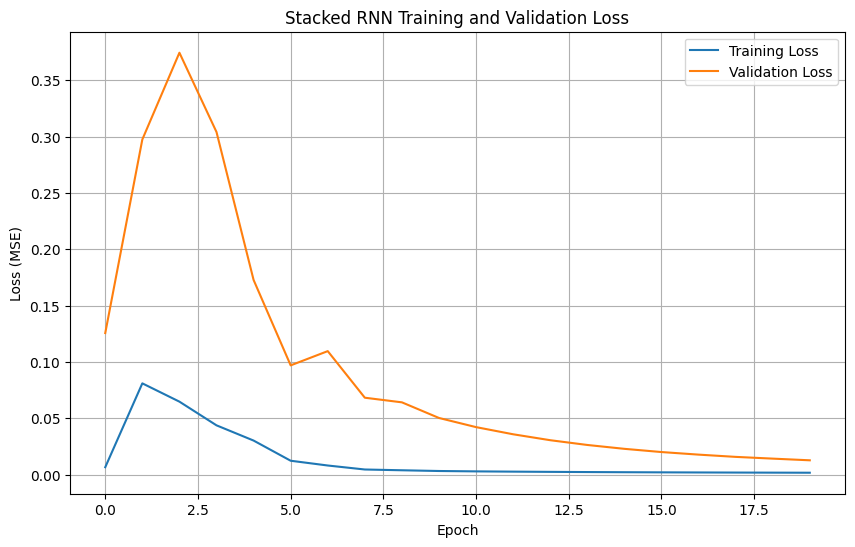

In [16]:
train_plot_loss(model, train_loader, val_loader, criterion, optimizer)

In [17]:
evaluate_model(model, test_loader)

Stacked RNN Test R2 Score: 0.2364
Stacked RNN Test MSE: 0.1454


### TASK 5: Bidirectional RNN Implementation

In [18]:
SEED = 69
torch.manual_seed(SEED)
np.random.seed(SEED)

In [19]:
class BidirectionalRNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super(BidirectionalRNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        # Forward RNN cells
        self.rnn_cells_forward = nn.ModuleList()
        self.rnn_cells_forward.append(CustomRNNCell(input_size, hidden_size))
        for _ in range(1, num_layers):
            self.rnn_cells_forward.append(CustomRNNCell(hidden_size, hidden_size))
        # Backward RNN cells
        self.rnn_cells_backward = nn.ModuleList()
        self.rnn_cells_backward.append(CustomRNNCell(input_size, hidden_size))
        for _ in range(1, num_layers):
            self.rnn_cells_backward.append(CustomRNNCell(hidden_size, hidden_size))
        # Fully connected layer (input size is 2 * hidden_size due to concatenation)
        self.fc = nn.Sequential(
            nn.Linear(2 * hidden_size, 64),
            nn.ReLU(),
            nn.Linear(64, output_size)
        )

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_size)
        batch_size = x.size(0)
        seq_len = x.size(1)
        # Forward pass
        hidden_states_forward = [None] * self.num_layers
        forward_outputs = []
        for t in range(seq_len):
            input_t = x[:, t, :]
            for layer_idx in range(self.num_layers):
                rnn_cell = self.rnn_cells_forward[layer_idx]
                hx = hidden_states_forward[layer_idx]
                new_hx = rnn_cell(input_t, hx)
                hidden_states_forward[layer_idx] = new_hx
                input_t = new_hx
            forward_outputs.append(new_hx)
        # Last hidden state of the last forward layer
        last_forward_hidden = forward_outputs[-1] # (batch_size, hidden_size)
        # Backward pass
        hidden_states_backward = [None] * self.num_layers
        backward_outputs = []
        # Process sequence in reverse order
        for t in range(seq_len - 1, -1, -1):
            input_t = x[:, t, :]
            for layer_idx in range(self.num_layers):
                rnn_cell = self.rnn_cells_backward[layer_idx]
                hx = hidden_states_backward[layer_idx]
                new_hx = rnn_cell(input_t, hx)
                hidden_states_backward[layer_idx] = new_hx
                input_t = new_hx
            backward_outputs.append(new_hx)
        # Last hidden state of the last backward layer (from the first element in reversed sequence)
        last_backward_hidden = backward_outputs[-1] # (batch_size, hidden_size)
        # Concatenate the last hidden states from forward and backward passes
        combined_hidden = torch.cat((last_forward_hidden, last_backward_hidden), dim=1) # (batch_size, 2 * hidden_size)
        # Pass through the fully connected layer
        output = self.fc(combined_hidden)
        return output

In [20]:
# Model parameters (same as before)
input_size = 1
hidden_size = 64
num_layers = 2
output_size = 1
learning_rate = 0.001

birnn_model = BidirectionalRNN(input_size, hidden_size, num_layers, output_size)
birnn_criterion = nn.MSELoss()
birnn_optimizer = optim.Adam(birnn_model.parameters(), lr=learning_rate)
print(f"Number of parameters in Bi-RNN: {sum(p.numel() for p in birnn_model.parameters() if p.requires_grad)}")

Number of parameters in Bi-RNN: 33537


Epoch [1/20], Bi-RNN Train Loss: 0.0060, Bi-RNN Val Loss: 0.0782
Epoch [2/20], Bi-RNN Train Loss: 0.0517, Bi-RNN Val Loss: 0.1270
Epoch [3/20], Bi-RNN Train Loss: 0.0588, Bi-RNN Val Loss: 0.1179
Epoch [4/20], Bi-RNN Train Loss: 0.0447, Bi-RNN Val Loss: 0.0672
Epoch [5/20], Bi-RNN Train Loss: 0.0291, Bi-RNN Val Loss: 0.0404
Epoch [6/20], Bi-RNN Train Loss: 0.0098, Bi-RNN Val Loss: 0.0303
Epoch [7/20], Bi-RNN Train Loss: 0.0053, Bi-RNN Val Loss: 0.0283
Epoch [8/20], Bi-RNN Train Loss: 0.0061, Bi-RNN Val Loss: 0.0315
Epoch [9/20], Bi-RNN Train Loss: 0.0049, Bi-RNN Val Loss: 0.0195
Epoch [10/20], Bi-RNN Train Loss: 0.0042, Bi-RNN Val Loss: 0.0219
Epoch [11/20], Bi-RNN Train Loss: 0.0035, Bi-RNN Val Loss: 0.0151
Epoch [12/20], Bi-RNN Train Loss: 0.0029, Bi-RNN Val Loss: 0.0141
Epoch [13/20], Bi-RNN Train Loss: 0.0021, Bi-RNN Val Loss: 0.0075
Epoch [14/20], Bi-RNN Train Loss: 0.0012, Bi-RNN Val Loss: 0.0088
Epoch [15/20], Bi-RNN Train Loss: 0.0016, Bi-RNN Val Loss: 0.0091
Epoch [16/20], Bi-R

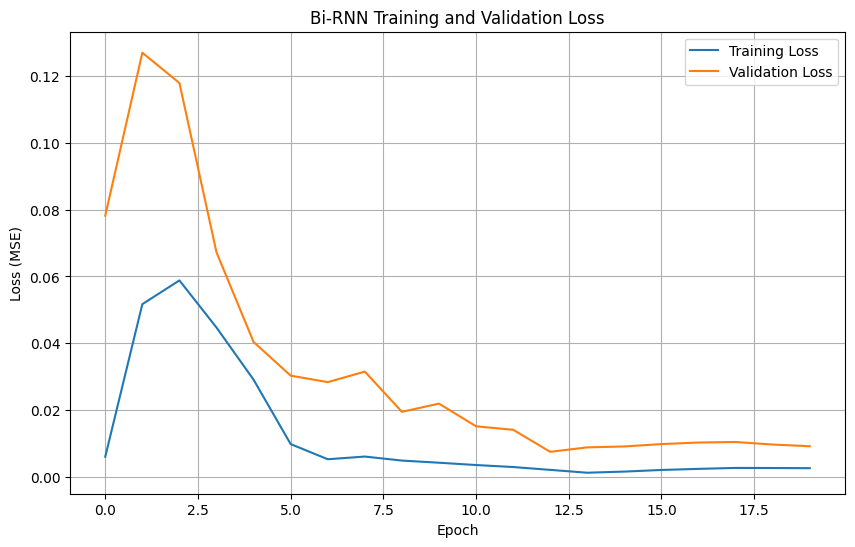

In [21]:
train_plot_loss(birnn_model, train_loader, val_loader, birnn_criterion, birnn_optimizer, label='Bi-RNN')

In [22]:
evaluate_model(birnn_model, test_loader, label='Bi-RNN')

Bi-RNN Test R2 Score: 0.4930
Bi-RNN Test MSE: 0.0965


### TASK 6: Attention-based RNN Implementation

In [23]:
SEED = 15
torch.manual_seed(SEED)
np.random.seed(SEED)

In [24]:
class AttentionRNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size):
        super(AttentionRNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        # Learnable attention vectors for odd and even timesteps
        k = 1.0 / math.sqrt(hidden_size)
        self.attn_vector_odd = nn.Parameter(torch.empty(hidden_size))
        nn.init.uniform_(self.attn_vector_odd, -k, k)
        self.attn_vector_even = nn.Parameter(torch.empty(hidden_size))
        nn.init.uniform_(self.attn_vector_even, -k, k)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Linear(64, output_size)
        )

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_size)
        # RNN output: (batch_size, seq_len, hidden_size)
        # h_n: (num_layers, batch_size, hidden_size)
        rnn_output, _ = self.rnn(x)
        batch_size, seq_len, _ = rnn_output.size()
        # Calculate attention scores for odd and even timesteps
        scores = torch.zeros(batch_size, seq_len, device=x.device)
        for t in range(seq_len):
            if (t + 1) % 2 != 0:  # Odd timestep
                # score = dot product (hidden_state_t, attn_vector_odd)
                scores[:, t] = torch.sum(rnn_output[:, t, :] * self.attn_vector_odd, dim=1)
            else:  # Even timestep
                # score = dot product (hidden_state_t, attn_vector_even)
                scores[:, t] = torch.sum(rnn_output[:, t, :] * self.attn_vector_even, dim=1)
        # softmax over the sequence dimension to get attention weights
        attention_weights = torch.softmax(scores, dim=1)
        attention_weights = attention_weights.unsqueeze(2) # (batch_size, seq_len, 1)
        # Compute context vector as weighted sum of rnn_output
        context_vector = torch.sum(rnn_output * attention_weights, dim=1) # (batch_size, hidden_size)
        output = self.fc(context_vector)
        return output

In [25]:
# Model parameters (same as before)
input_size = 1
hidden_size = 64
num_layers = 2
output_size = 1
learning_rate = 0.001

attn_rnn_model = AttentionRNN(input_size, hidden_size, num_layers, output_size)
attn_rnn_criterion = nn.MSELoss()
attn_rnn_optimizer = optim.Adam(attn_rnn_model.parameters(), lr=learning_rate)
print(f"Number of parameters in Attention-RNN: {sum(p.numel() for p in attn_rnn_model.parameters() if p.requires_grad)}")

Number of parameters in Attention-RNN: 16961


Epoch [1/20], Attn-RNN Train Loss: 0.0066, Attn-RNN Val Loss: 0.1108
Epoch [2/20], Attn-RNN Train Loss: 0.0816, Attn-RNN Val Loss: 0.1167
Epoch [3/20], Attn-RNN Train Loss: 0.0850, Attn-RNN Val Loss: 0.1325
Epoch [4/20], Attn-RNN Train Loss: 0.0762, Attn-RNN Val Loss: 0.2029
Epoch [5/20], Attn-RNN Train Loss: 0.0524, Attn-RNN Val Loss: 0.2383
Epoch [6/20], Attn-RNN Train Loss: 0.0262, Attn-RNN Val Loss: 0.0998
Epoch [7/20], Attn-RNN Train Loss: 0.0097, Attn-RNN Val Loss: 0.0543
Epoch [8/20], Attn-RNN Train Loss: 0.0072, Attn-RNN Val Loss: 0.0556
Epoch [9/20], Attn-RNN Train Loss: 0.0068, Attn-RNN Val Loss: 0.0553
Epoch [10/20], Attn-RNN Train Loss: 0.0050, Attn-RNN Val Loss: 0.0325
Epoch [11/20], Attn-RNN Train Loss: 0.0039, Attn-RNN Val Loss: 0.0286
Epoch [12/20], Attn-RNN Train Loss: 0.0031, Attn-RNN Val Loss: 0.0226
Epoch [13/20], Attn-RNN Train Loss: 0.0026, Attn-RNN Val Loss: 0.0184
Epoch [14/20], Attn-RNN Train Loss: 0.0023, Attn-RNN Val Loss: 0.0157
Epoch [15/20], Attn-RNN Train

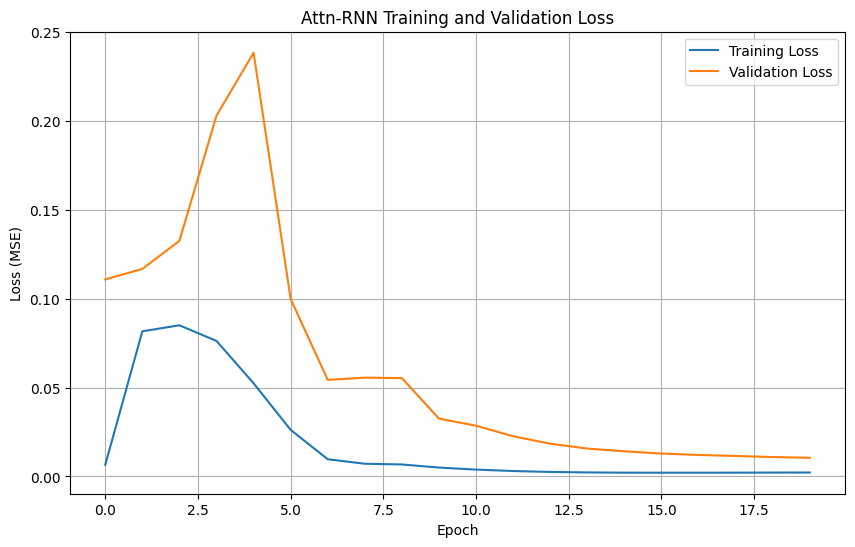

In [26]:
train_plot_loss(attn_rnn_model, train_loader, val_loader, attn_rnn_criterion, attn_rnn_optimizer, label='Attn-RNN', clip_grad=True)

In [27]:
evaluate_model(attn_rnn_model, test_loader, label='Attn-RNN')

Attn-RNN Test R2 Score: 0.4048
Attn-RNN Test MSE: 0.1133


Results

| Stacked RNN | Bi-RNN |  Attn-RNN |
| --- | --- | --- |
| 0.2364 | 0.4930 | 0.4048 |